In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout,
    Concatenate,
    LSTM,
    Bidirectional,
    BatchNormalization,
    MultiHeadAttention,
    LayerNormalization)

MAX_NB_WORDS = 20000
MAX_SEQUENCE_LENGTH = 100
EMBEDDING_DIM = 300

In [ ]:
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip -O /content/wiki-news-300d-1M.vec.zip
!unzip -q /content/wiki-news-300d-1M.vec.zip -d /content/
!ls -lh /content/wiki-news-300d-1M.vec

--2026-06-21 12:39:48--  https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 18.173.132.13, 18.173.132.81, 18.173.132.6, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|18.173.132.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 681808098 (650M) [application/zip]
Saving to: ‘/content/wiki-news-300d-1M.vec.zip’

/content/wiki-news- 100%[===================>] 650.22M   112MB/s    in 4.0s    

2026-06-21 12:39:52 (161 MB/s) - ‘/content/wiki-news-300d-1M.vec.zip’ saved [681808098/681808098]

-rw-r--r-- 1 root root 2.2G Mar 14  2018 /content/wiki-news-300d-1M.vec


In [ ]:
train_df = pd.read_csv("train_preprocessed.csv")
valid_df = pd.read_csv("valid_preprocessed.csv")
test_df = pd.read_csv("test_preprocessed.csv")

In [ ]:
text_columns = ["Statement","Subjects","Speaker","Speaker_Job","State","Party","Context"]

for df in [train_df, valid_df, test_df]:
    df["Combined_Text"] = (df[text_columns].fillna("").agg(" ".join, axis=1))

In [ ]:
binary_map = {"pants-fire":0,"false":0,"barely-true":0,"half-true":1,"mostly-true":1,"true":1}

for df in [train_df, valid_df, test_df]:
    df["Label"] = (df["Label"].astype(str).str.lower().str.strip())

y_train = train_df["Label"].map(binary_map).values
y_valid = valid_df["Label"].map(binary_map).values
y_test = test_df["Label"].map(binary_map).values

In [ ]:
tokenizer = Tokenizer(num_words=MAX_NB_WORDS,oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["Combined_Text"])
word_index = tokenizer.word_index

print("Vocabulary Size:", len(word_index))

train_sequences = tokenizer.texts_to_sequences(train_df["Combined_Text"])
valid_sequences = tokenizer.texts_to_sequences(valid_df["Combined_Text"])
test_sequences = tokenizer.texts_to_sequences(test_df["Combined_Text"])

X_train = pad_sequences(train_sequences,maxlen=MAX_SEQUENCE_LENGTH,padding="post",truncating="post")
X_valid = pad_sequences(valid_sequences,maxlen=MAX_SEQUENCE_LENGTH,padding="post",truncating="post")
X_test = pad_sequences(test_sequences,maxlen=MAX_SEQUENCE_LENGTH,padding="post",truncating="post")

Vocabulary Size: 15199


In [ ]:
CREDIT_COLS = ["Barely_True_Count","False_Count","Half_True_Count","Mostly_True_Count", "Pants_On_fire_Count"]

X_train_credit = train_df[CREDIT_COLS].fillna(0).values
X_valid_credit  = valid_df[CREDIT_COLS].fillna(0).values
X_test_credit   = test_df[CREDIT_COLS].fillna(0).values

print("Credit features shape: ",X_train_credit.shape)

scaler = StandardScaler()
X_train_credit = scaler.fit_transform(X_train_credit)
X_valid_credit  = scaler.transform(X_valid_credit)
X_test_credit   = scaler.transform(X_test_credit)

CREDIT_DIM = X_train_credit.shape[1]

Credit features shape:  (10138, 5)


In [ ]:
FASTTEXT_PATH = "wiki-news-300d-1M.vec"

def load_fasttext(filepath, word_index):
    embeddings = {}

    with open(filepath,"r",encoding="utf-8",errors="ignore") as f:
        next(f)
        for line in f:
            values = line.rstrip().split(" ")
            word = values[0]
            if word in word_index:
                embeddings[word] = np.asarray(values[1:],dtype="float32")

    return embeddings

fasttext_embeddings = load_fasttext(FASTTEXT_PATH,word_index)
vocab_size = len(word_index) + 1
embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM))

for word, idx in word_index.items():
    vector = fasttext_embeddings.get(word)
    if vector is not None:
        embedding_matrix[idx] = vector

In [ ]:
class_weights = compute_class_weight(class_weight="balanced",classes=np.unique(y_train),y=y_train)
class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(1.1416666666666666), 1: np.float64(0.8896103896103896)}


In [ ]:
def build_model(vocab_size, embedding_matrix, credit_dim):

  embedding_layer = Embedding(input_dim=vocab_size,output_dim=EMBEDDING_DIM,weights=[embedding_matrix],trainable=False, name="fasttext_embedding")

  text_input = Input(shape=(MAX_SEQUENCE_LENGTH,) , name="text_input")
  embedded = embedding_layer(text_input)

  conv2 = Conv1D(128,2,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv3 = Conv1D(128,3,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv4 = Conv1D(128,4,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv5 = Conv1D(128,5,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv6 = Conv1D(128,6,activation="relu",kernel_regularizer=l2(1e-4))(embedded)

  pool2 = GlobalMaxPooling1D()(conv2)
  pool3 = GlobalMaxPooling1D()(conv3)
  pool4 = GlobalMaxPooling1D()(conv4)
  pool5 = GlobalMaxPooling1D()(conv5)
  pool6 = GlobalMaxPooling1D()(conv6)

  cnn_features = Concatenate()([pool2,pool3,pool4,pool5,pool6])
  cnn_features = BatchNormalization()(cnn_features)
  cnn_features = Dropout(0.3)(cnn_features)

  lstm_features = Bidirectional(LSTM(128,return_sequences=True,dropout=0.2,recurrent_dropout=0.1))(embedded)
  lstm_features = Bidirectional(LSTM(64,return_sequences=True,dropout=0.2,recurrent_dropout=0.1))(lstm_features)

  attn_out = MultiHeadAttention(num_heads=4,key_dim=32,dropout=0.1)(lstm_features,lstm_features)
  attn_out = LayerNormalization()(attn_out + lstm_features)

  lstm_feature = GlobalAveragePooling1D()(attn_out)
  lstm_feature = BatchNormalization()(lstm_feature)
  lstm_feature = Dropout(0.3)(lstm_feature)

  credit_input = Input(shape=(credit_dim,), name="credit_input")
  cred = Dense(32, activation="relu",kernel_regularizer=l2(1e-4))(credit_input)
  cred = BatchNormalization()(cred)
  cred = Dropout(0.3)(cred)
  cred = Dense(16, activation="relu")(cred)

  merged = Concatenate()([cnn_features,lstm_feature,cred])

  x = Dense(256, activation="relu", kernel_regularizer=l2(1e-4))(merged)
  x = BatchNormalization()(x)
  x = Dropout(0.4)(x)

  x = Dense(128, activation="relu", kernel_regularizer=l2(1e-4))(x)
  x = BatchNormalization()(x)
  x = Dropout(0.3)(x)

  x = Dense(64, activation="relu")(x)
  x = Dropout(0.2)(x)

  output = Dense(2, activation="softmax")(x)

  return Model(inputs=[text_input, credit_input], outputs=output)

model = build_model(vocab_size, embedding_matrix, CREDIT_DIM)

model.compile(
    optimizer=Adam(learning_rate=1e-3, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fasttext_embedding  │ (None, 100, 300)  │  4,560,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 100, 256)  │    439,296 │ fasttext_embeddi… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 100, 128)  │    164,352 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 100, 128)  │     66,048 │ bidirectional_1[… │
│ (MultiHeadAttentio… │                   │            │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 99, 128)   │     76,928 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 98, 128)   │    115,328 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 97, 128)   │    153,728 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 96, 128)   │    192,128 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 95, 128)   │    230,528 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 100, 128)  │          0 │ multi_head_atten… │
│                     │                   │            │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ credit_input        │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_1[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_2[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_3[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_4[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 100, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 6,246,290 (23.83 MB)

 Trainable params: 1,683,922 (6.42 MB)

 Non-trainable params: 4,562,368 (17.40 MB)

In [ ]:
early_stop_1 = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
lr_plateau_1 = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6,verbose=1)

history_1 = model.fit([X_train, X_train_credit], y_train,
    validation_data=([X_valid, X_valid_credit], y_valid),
    epochs=3,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop_1, lr_plateau_1])

model.get_layer("fasttext_embedding").trainable = True

model.compile(
    optimizer=Adam(learning_rate=1e-4, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

early_stop_2 = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)
checkpoint = ModelCheckpoint("best_binary_fasttext_lstm.keras",save_best_only=True,monitor="val_accuracy",verbose=1)
lr_plateau_2 = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6, verbose=1)

history_2 = model.fit([X_train,X_train_credit],y_train,
    validation_data=([X_valid, X_valid_credit],y_valid),
    initial_epoch=3,
    epochs=25,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop_2,checkpoint,lr_plateau_2])

model.save("binary_fasttext_lstm.keras")

Epoch 1/3
317/317 ━━━━━━━━━━━━━━━━━━━━ 432s 1s/step - accuracy: 0.5487 - loss: 0.9469 - val_accuracy: 0.5629 - val_loss: 0.8457 - learning_rate: 0.0010
Epoch 2/3
317/317 ━━━━━━━━━━━━━━━━━━━━ 435s 1s/step - accuracy: 0.6053 - loss: 0.8521 - val_accuracy: 0.6226 - val_loss: 0.8219 - learning_rate: 0.0010
Epoch 3/3
317/317 ━━━━━━━━━━━━━━━━━━━━ 405s 1s/step - accuracy: 0.6636 - loss: 0.8013 - val_accuracy: 0.6549 - val_loss: 0.7925 - learning_rate: 0.0010
Epoch 4/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7258 - loss: 0.7204
Epoch 4: val_accuracy improved from None to 0.66588, saving model to best_binary_fasttext_lstm.keras

Epoch 4: finished saving model to best_binary_fasttext_lstm.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 452s 1s/step - accuracy: 0.7410 - loss: 0.7066 - val_accuracy: 0.6659 - val_loss: 0.7845 - learning_rate: 1.0000e-04
Epoch 5/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7902 - loss: 0.6429
Epoch 5: val_accuracy did not improve from 0.66588
317/317 ━

In [ ]:
test_loss, test_acc = model.evaluate([X_test,X_test_credit],y_test)
print("Test Accuracy:", test_acc)

y_pred = model.predict([X_test,X_test_credit])
y_pred = np.argmax(y_pred,axis=1)
print(classification_report(y_test,y_pred,target_names=["Fake","Real"]))

40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 265ms/step - accuracy: 0.6720 - loss: 0.7944
Test Accuracy: 0.671999990940094
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 291ms/step
              precision    recall  f1-score   support

        Fake       0.61      0.68      0.65       549
        Real       0.73      0.66      0.69       701

    accuracy                           0.67      1250
   macro avg       0.67      0.67      0.67      1250
weighted avg       0.68      0.67      0.67      1250



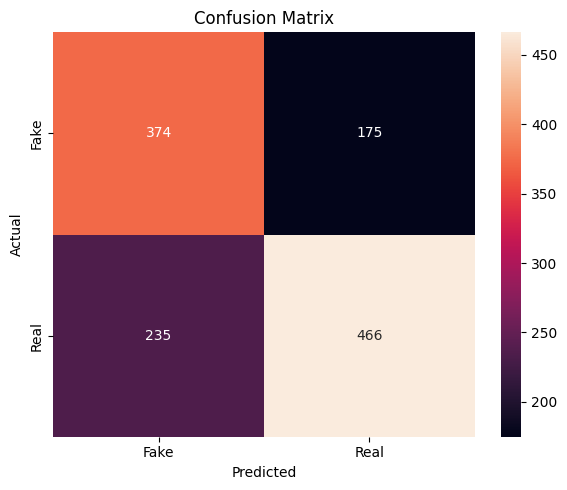

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=["Fake","Real"],yticklabels=["Fake","Real"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

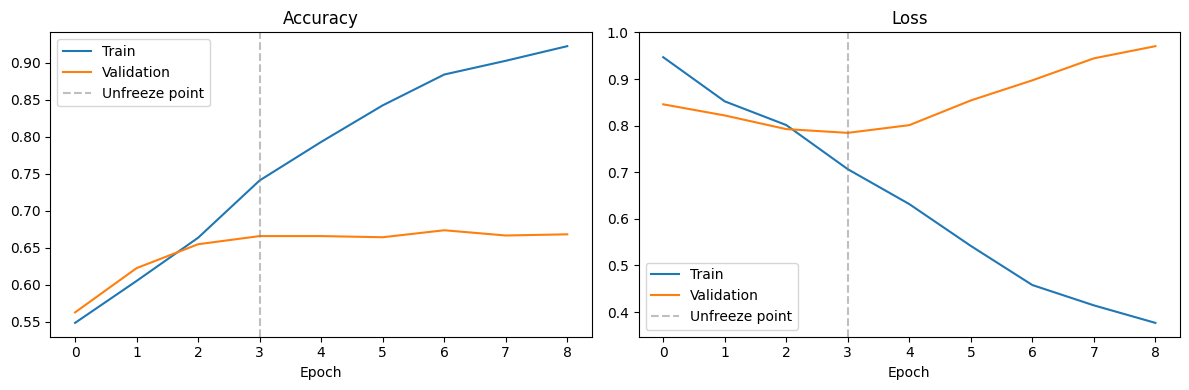

In [ ]:
merged_history = {"accuracy" : history_1.history["accuracy"] + history_2.history["accuracy"],
    "val_accuracy": history_1.history["val_accuracy"] + history_2.history["val_accuracy"],
    "loss" : history_1.history["loss"] + history_2.history["loss"],
    "val_loss" : history_1.history["val_loss"] + history_2.history["val_loss"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(merged_history[metric], label="Train")
    ax.plot(merged_history[f"val_{metric}"], label="Validation")
    ax.axvline(x=3, color="gray", linestyle="--", alpha=0.5, label="Unfreeze point")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
nrc = pd.read_csv("NRC-Emotion-Lexicon-Wordlevel-v0.92.txt",sep="\t",header=None,names=["word", "emotion", "association"])
nrc = nrc[nrc["association"] == 1]

emotion_dict = {}
emotion_labels = ['anger','anticipation','disgust','fear','joy','sadness','surprise','trust','positive','negative']

for _, row in nrc.iterrows():
    word = row["word"]
    emotion = row["emotion"]

    if word not in emotion_dict:
        emotion_dict[word] = []

    emotion_dict[word].append(emotion)

def extract_emotions(text):
    counts = Counter()
    words = str(text).split()

    for word in words:
        if word in emotion_dict:
            for emotion in emotion_dict[word]:
                if emotion in emotion_labels:
                    counts[emotion] += 1

    return [counts[e] for e in emotion_labels]

emotion_features_train = np.array(train_df["Combined_Text"].apply(extract_emotions).tolist())
emotion_features_valid = np.array(valid_df["Combined_Text"].apply(extract_emotions).tolist())
emotion_features_test = np.array(test_df["Combined_Text"].apply(extract_emotions).tolist())

emo_scaler = StandardScaler()
emotion_features_train = emo_scaler.fit_transform(emotion_features_train)
emotion_features_valid = emo_scaler.transform(emotion_features_valid)
emotion_features_test = emo_scaler.transform(emotion_features_test)

EMOTION_DIM = emotion_features_train.shape[1]
print("Emotion features shape: ",emotion_features_train.shape)

Emotion features shape:  (10138, 10)


In [ ]:
def build_model(vocab_size, embedding_matrix, credit_dim, emotion_dim):

  embedding_layer = Embedding(input_dim=vocab_size,output_dim=EMBEDDING_DIM,weights=[embedding_matrix],trainable=False, name="fasttext_embedding")

  text_input = Input(shape=(MAX_SEQUENCE_LENGTH,) , name="text_input")
  embedded = embedding_layer(text_input)

  conv2 = Conv1D(128,2,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv3 = Conv1D(128,3,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv4 = Conv1D(128,4,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv5 = Conv1D(128,5,activation="relu",kernel_regularizer=l2(1e-4))(embedded)
  conv6 = Conv1D(128,6,activation="relu",kernel_regularizer=l2(1e-4))(embedded)

  pool2 = GlobalMaxPooling1D()(conv2)
  pool3 = GlobalMaxPooling1D()(conv3)
  pool4 = GlobalMaxPooling1D()(conv4)
  pool5 = GlobalMaxPooling1D()(conv5)
  pool6 = GlobalMaxPooling1D()(conv6)

  cnn_features = Concatenate()([pool2,pool3,pool4,pool5,pool6])
  cnn_features = BatchNormalization()(cnn_features)
  cnn_features = Dropout(0.3)(cnn_features)

  lstm_features = Bidirectional(LSTM(128,return_sequences=True,dropout=0.2,recurrent_dropout=0.1))(embedded)
  lstm_features = Bidirectional(LSTM(64,return_sequences=True,dropout=0.2,recurrent_dropout=0.1))(lstm_features)

  attn_out = MultiHeadAttention(num_heads=4,key_dim=32,dropout=0.1)(lstm_features,lstm_features)
  attn_out = LayerNormalization()(attn_out + lstm_features)

  lstm_feature = GlobalAveragePooling1D()(attn_out)
  lstm_feature = BatchNormalization()(lstm_feature)
  lstm_feature = Dropout(0.3)(lstm_feature)

  credit_input = Input(shape=(credit_dim,), name="credit_input")
  credit_features = Dense(32, activation="relu",kernel_regularizer=l2(1e-4))(credit_input)
  credit_features = BatchNormalization()(credit_features)
  credit_features = Dropout(0.3)(credit_features)
  credit_features = Dense(16, activation="relu")(credit_features)

  emotion_input = Input(shape=(emotion_dim,), name="emotion_input")
  emotion_features = Dense(32, activation="relu", kernel_regularizer=l2(1e-4))(emotion_input)
  emotion_features = BatchNormalization()(emotion_features)
  emotion_features = Dropout(0.2)(emotion_features)
  emotion_features = Dense(16, activation="relu")(emotion_features)

  merged = Concatenate()([cnn_features,lstm_feature,credit_features,emotion_features])

  x = Dense(256, activation="relu", kernel_regularizer=l2(1e-4))(merged)
  x = BatchNormalization()(x)
  x = Dropout(0.4)(x)

  x = Dense(128, activation="relu", kernel_regularizer=l2(1e-4))(x)
  x = BatchNormalization()(x)
  x = Dropout(0.3)(x)

  x = Dense(64, activation="relu")(x)
  x = Dropout(0.2)(x)

  output = Dense(2, activation="softmax")(x)

  return Model(inputs=[text_input, credit_input, emotion_input], outputs=output)

model1 = build_model(vocab_size, embedding_matrix, CREDIT_DIM, EMOTION_DIM)

model1.compile(
    optimizer=Adam(learning_rate=1e-3, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

model1.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fasttext_embedding  │ (None, 100, 300)  │  4,560,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 100, 256)  │    439,296 │ fasttext_embeddi… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 100, 128)  │    164,352 │ bidirectional_2[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 100, 128)  │     66,048 │ bidirectional_3[… │
│ (MultiHeadAttentio… │                   │            │ bidirectional_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 99, 128)   │     76,928 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 98, 128)   │    115,328 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 97, 128)   │    153,728 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 96, 128)   │    192,128 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 95, 128)   │    230,528 │ fasttext_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 100, 128)  │          0 │ multi_head_atten… │
│                     │                   │            │ bidirectional_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ credit_input        │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emotion_input       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_5[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_6[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_7[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_8[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_9[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 6,251,394 (23.85 MB)

 Trainable params: 1,688,962 (6.44 MB)

 Non-trainable params: 4,562,432 (17.40 MB)

In [ ]:
early_stop_1 = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
lr_plateau_1 = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6,verbose=1)

history_1 = model1.fit([X_train, X_train_credit, emotion_features_train], y_train,
    validation_data=([X_valid, X_valid_credit, emotion_features_valid], y_valid),
    epochs=3,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop_1, lr_plateau_1])

model1.get_layer("fasttext_embedding").trainable = True

model1.compile(
    optimizer=Adam(learning_rate=1e-4, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

early_stop_2 = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)
checkpoint = ModelCheckpoint("best_emotion_lstm.keras",save_best_only=True,monitor="val_accuracy",verbose=1)
lr_plateau_2 = ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6, verbose=1)

history_2 = model1.fit([X_train,X_train_credit, emotion_features_train],y_train,
    validation_data=([X_valid, X_valid_credit, emotion_features_valid],y_valid),
    initial_epoch=3,
    epochs=25,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop_2,checkpoint,lr_plateau_2])

model1.save("emotion_lstm.keras")

Epoch 1/3
317/317 ━━━━━━━━━━━━━━━━━━━━ 437s 1s/step - accuracy: 0.5561 - loss: 0.9448 - val_accuracy: 0.6116 - val_loss: 0.8295 - learning_rate: 0.0010
Epoch 2/3
317/317 ━━━━━━━━━━━━━━━━━━━━ 437s 1s/step - accuracy: 0.6014 - loss: 0.8544 - val_accuracy: 0.6289 - val_loss: 0.8190 - learning_rate: 0.0010
Epoch 3/3
317/317 ━━━━━━━━━━━━━━━━━━━━ 448s 1s/step - accuracy: 0.6660 - loss: 0.7976 - val_accuracy: 0.6407 - val_loss: 0.8042 - learning_rate: 0.0010
Epoch 4/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7470 - loss: 0.7114
Epoch 4: val_accuracy improved from None to 0.68082, saving model to best_emotion_lstm.keras

Epoch 4: finished saving model to best_emotion_lstm.keras
317/317 ━━━━━━━━━━━━━━━━━━━━ 469s 1s/step - accuracy: 0.7521 - loss: 0.6960 - val_accuracy: 0.6808 - val_loss: 0.7710 - learning_rate: 1.0000e-04
Epoch 5/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7918 - loss: 0.6342
Epoch 5: val_accuracy improved from 0.68082 to 0.69811, saving model to best

In [ ]:
test_loss, test_acc = model1.evaluate([X_test,X_test_credit,emotion_features_test],y_test)
print("Test Accuracy:", test_acc)

y_pred = model1.predict([X_test,X_test_credit,emotion_features_test])
y_pred = np.argmax(y_pred,axis=1)
print(classification_report(y_test,y_pred,target_names=["Fake","Real"]))

40/40 ━━━━━━━━━━━━━━━━━━━━ 20s 519ms/step - accuracy: 0.7056 - loss: 0.7827
Test Accuracy: 0.7056000232696533
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 302ms/step
              precision    recall  f1-score   support

        Fake       0.67      0.66      0.66       549
        Real       0.73      0.74      0.74       701

    accuracy                           0.71      1250
   macro avg       0.70      0.70      0.70      1250
weighted avg       0.71      0.71      0.71      1250



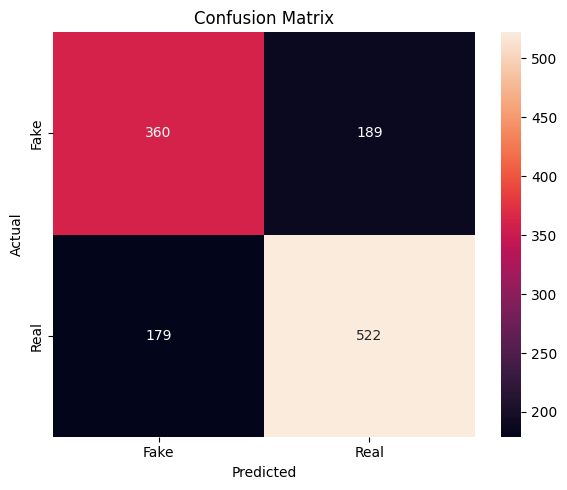

In [ ]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=["Fake","Real"],yticklabels=["Fake","Real"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

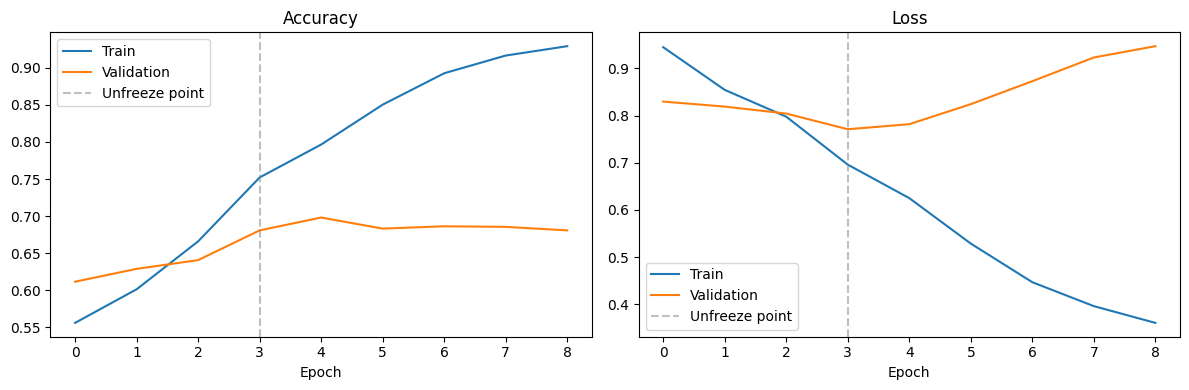

In [ ]:
merged_history = {"accuracy" : history_1.history["accuracy"] + history_2.history["accuracy"],
    "val_accuracy": history_1.history["val_accuracy"] + history_2.history["val_accuracy"],
    "loss" : history_1.history["loss"] + history_2.history["loss"],
    "val_loss" : history_1.history["val_loss"] + history_2.history["val_loss"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(merged_history[metric], label="Train")
    ax.plot(merged_history[f"val_{metric}"], label="Validation")
    ax.axvline(x=3, color="gray", linestyle="--", alpha=0.5, label="Unfreeze point")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()